# 02 - Baseline: Dummy Classifier

In [1]:
import sys, time, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as C
from src.features import get_xy
from src.pipeline import build_model, predict_proba
from src.evaluation import evaluate_and_save, plot_curves, score_at, best_threshold
from sklearn.metrics import average_precision_score

df = pd.read_parquet(C.CLEAN_PATH)
X_train, y_train, _ = get_xy(df, "train")
X_val, y_val, _ = get_xy(df, "val")
X_test, y_test, _ = get_xy(df, "test")
print(X_train.shape, X_val.shape, X_test.shape)

(384548, 13) (81129, 13) (80445, 13)


The dummy model always predicts the majority class (no sepsis). Every other model must beat this.

In [2]:
model = build_model("dummy")
model.fit(X_train, y_train)
best_params = {"strategy": "prior"}

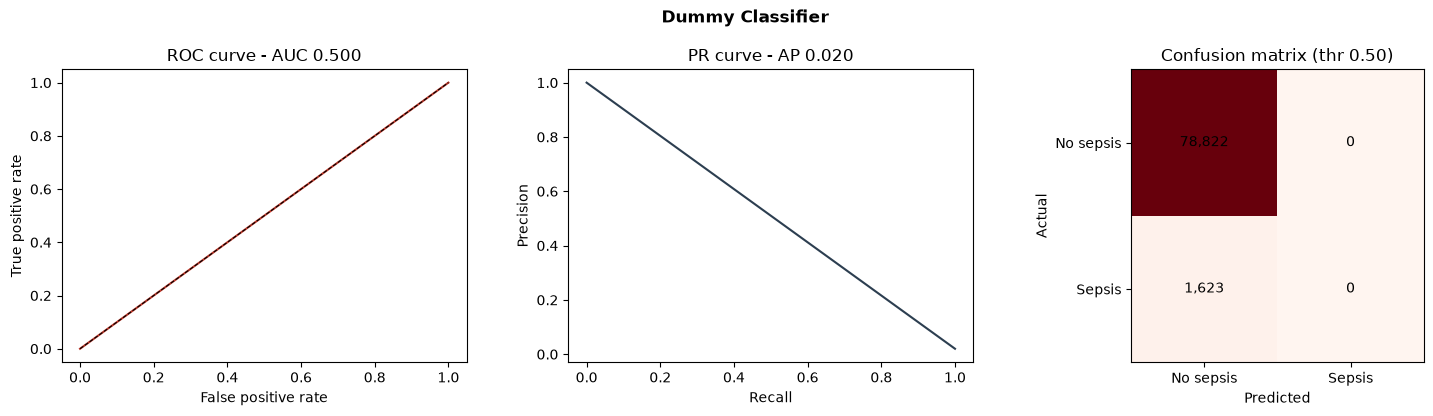

,val,test
roc_auc,0.500,0.50
pr_auc,0.022,0.02
precision,0.000,0.00
recall,0.000,0.00
specificity,1.000,1.00
f1,0.000,0.00
f2,0.000,0.00
balanced_accuracy,0.500,0.50


In [3]:
p_val = predict_proba(model, X_val)
p_test = predict_proba(model, X_test)
# fixed threshold 0.5 -> always predicts "no sepsis"
res = evaluate_and_save("dummy", y_val, p_val, y_test, p_test, extra={"params": best_params}, threshold=0.5)
plot_curves(y_test, p_test, "Dummy Classifier", 0.5)
pd.DataFrame(res).loc[["roc_auc","pr_auc","precision","recall","specificity","f1","f2","balanced_accuracy"], ["val","test"]].round(3)

Accuracy looks high (about 98%) but recall is 0. This is why we use PR-AUC, recall and F2 and not accuracy.